# TIC Kids Online Brasil 2025 — H1: mediação parental e riscos online

**Pergunta:** práticas de orientação, mediação e restrição parental estão associadas a menor exposição a riscos online entre crianças e adolescentes de 9 a 17 anos?

Este notebook usa a base integrada: cada linha possui respostas do bloco do responsável e da criança. O foco aqui é apenas H1. A análise é observacional; associações não demonstram que a mediação causou redução de risco. Antes de testar hipóteses, vamos documentar o dicionário, a codificação dos itens, universos de resposta e limitações de mensuração.

**Plano amostral:** `PESO` é usado nas estimativas descritivas e em modelos ponderados. A busca também verificará estrato, UPA e pesos replicados. P-valores convencionais/robustos são aproximações se o desenho complexo não puder ser reproduzido integralmente.


## 1. Ambiente e descoberta dos arquivos
Nesta primeira célula verificamos dependências, caminhos, arquivos e os formatos disponíveis. A leitura começa pelo dicionário e pela base integrada de crianças.

In [33]:
from pathlib import Path
import csv, hashlib, warnings
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT=Path.cwd()
if not (ROOT/'criancas').exists():
    ROOT=Path('/home/ymws/Documentos/mestrado/estatistica/internet')
def list_files(folder):
    return sorted(p for p in (ROOT/folder).rglob('*') if p.is_file())
for folder in ['criancas/dicionario','criancas/microdados','criancas/relatorio','pais/dicionario','pais/microdados']:
    print(f'\n{folder}')
    for p in list_files(folder): print(' •',p.relative_to(ROOT))



criancas/dicionario
 • criancas/dicionario/tic_kids_online_brasil_2025_dicionario_de_variaveis_v1.0 (1).ods
 • criancas/dicionario/tic_kids_online_brasil_2025_dicionario_de_variaveis_v1.0 (1).xlsx

criancas/microdados
 • criancas/microdados/tic_kids_online_brasil_2025_base_de_microdados_v1.0 (1).csv

criancas/relatorio
 • criancas/relatorio/tic_kids_online_2025_relatorio_metodologico_v1.0.docx
 • criancas/relatorio/tic_kids_online_2025_relatorio_metodologico_v1.0.odt
 • criancas/relatorio/tic_kids_online_2025_relatorio_metodologico_v1.0.pdf

pais/dicionario
 • pais/dicionario/tic_kids_online_brasil_2025_dicionario_de_variaveis_v1.0.ods
 • pais/dicionario/tic_kids_online_brasil_2025_dicionario_de_variaveis_v1.0.xlsx

pais/microdados
 • pais/microdados/tic_kids_online_brasil_2025_base_de_microdados_v1.0 (2).csv
 • pais/microdados/tic_kids_online_brasil_2025_base_de_microdados_v1.0.RData
 • pais/microdados/tic_kids_online_brasil_2025_base_de_microdados_v1.0.sav


## 2. Dicionário e leitura da base
A base infantil contém blocos separados de perguntas para responsáveis e crianças. O dicionário orientará nomes, descrições e códigos. A célula detecta delimitador e encoding do CSV.

In [34]:
# Localiza o CSV integrado e os dicionários tabulares.
csv_files=[p for p in list_files('criancas/microdados') if p.suffix.lower()=='.csv']
if not csv_files: raise FileNotFoundError('CSV dos microdados não encontrado em criancas/microdados/.')
data_path=csv_files[0]
raw=data_path.read_bytes()[:20000]
try: sample=raw.decode('utf-8-sig'); encoding='utf-8-sig'
except UnicodeDecodeError: sample=raw.decode('latin-1'); encoding='latin-1'
delimiter=csv.Sniffer().sniff(sample,delimiters=';,\t|').delimiter
print('Arquivo:',data_path.name,'| encoding:',encoding,'| delimitador:',repr(delimiter))
df0=pd.read_csv(data_path,sep=delimiter,encoding=encoding,dtype=str,low_memory=False)
print('Dimensões:',df0.shape,'| SHA256:',hashlib.sha256(data_path.read_bytes()).hexdigest())

dict_files=[p for p in list_files('criancas/dicionario') if p.suffix.lower() in {'.xlsx','.xls','.ods'}]
dict_parts=[]
for path in dict_files:
    try:
        for sheet in pd.ExcelFile(path).sheet_names:
            part=pd.read_excel(path,sheet_name=sheet,header=None)
            part['_arquivo']=path.name; dict_parts.append(part)
    except Exception as exc: print('Falha ao ler dicionário',path.name,exc)
dict_df=pd.concat(dict_parts,ignore_index=True) if dict_parts else pd.DataFrame()
varmap={}
for _,row in dict_df.iterrows():
    if len(row)<5 or pd.isna(row.iloc[1]): continue
    name=str(row.iloc[1]).strip()
    if name in df0.columns:
        varmap[name]={'descricao':str(row.iloc[2]) if pd.notna(row.iloc[2]) else '',
                      'tipo':str(row.iloc[3]) if pd.notna(row.iloc[3]) else '',
                      'rotulos':str(row.iloc[4]) if pd.notna(row.iloc[4]) else ''}
print('Variáveis descritas no dicionário:',len(varmap),'de',len(df0.columns))


Arquivo: tic_kids_online_brasil_2025_base_de_microdados_v1.0 (1).csv | encoding: utf-8-sig | delimitador: ';'
Dimensões: (2642, 569) | SHA256: dd584e11930e6316850912a6c8d259bb8ba31b5b4677eb40ea99c56a30dde53e
Falha ao ler dicionário tic_kids_online_brasil_2025_dicionario_de_variaveis_v1.0 (1).ods Missing optional dependency 'odfpy'.  Use pip or conda to install odfpy.
Falha ao ler dicionário tic_kids_online_brasil_2025_dicionario_de_variaveis_v1.0 (1).xlsx Missing optional dependency 'openpyxl'.  Use pip or conda to install openpyxl.
Variáveis descritas no dicionário: 0 de 569


### 2.1 Conferência de identificadores e plano amostral
Não assumimos que nomes usuais como `ESTRATO` e `UPA` existam. Também listamos as colunas `rep*`; elas só serão tratadas como pesos replicados se o dicionário ou documentação confirmar essa interpretação.

In [35]:
id_cols=[c for c in ['QUEST','ID_DOMICILIO','ID_MORADOR'] if c in df0.columns]
sample_cols=[c for c in df0.columns if any(k in c.upper() for k in ['PESO','ESTRAT','UPA','PSU','CLUSTER'])]
rep_cols=[c for c in df0.columns if c.lower().startswith('rep') and c[3:].isdigit()]
print('Identificadores:',id_cols)
print('Campos aparentes de plano amostral:',sample_cols)
print('Colunas com prefixo rep:',len(rep_cols),rep_cols[:10])
if id_cols: print('Registros com ID duplicado na chave composta:',df0.duplicated(id_cols).sum())
print('Descrição de PESO:',varmap.get('PESO',{}))
print('A análise não presumirá que rep1…repN sejam replicate weights sem documentação explícita.')


Identificadores: ['QUEST', 'ID_DOMICILIO', 'ID_MORADOR']
Campos aparentes de plano amostral: ['PESO']
Colunas com prefixo rep: 200 ['rep1', 'rep2', 'rep3', 'rep4', 'rep5', 'rep6', 'rep7', 'rep8', 'rep9', 'rep10']
Registros com ID duplicado na chave composta: 0
Descrição de PESO: {}
A análise não presumirá que rep1…repN sejam replicate weights sem documentação explícita.


## 3. Preparação e qualidade dos dados
Manteremos `df0` intacto como cópia bruta. A função `num_valid()` converte códigos numéricos e trata sentinelas como missing somente nas análises. Isso evita transformar `97/98/99` em respostas válidas.

In [36]:
MISSING_CODES={'97','98','99','88','-1','-2','Não sabe','Não respondeu','Não se aplica','Não entendeu'}
def num_valid(variable):
    """Converte uma variável numérica e remove códigos de missing/inválidos conhecidos."""
    if variable not in df0.columns: return pd.Series(np.nan,index=df0.index,dtype=float)
    s=df0[variable].astype('string').str.strip()
    s=s.mask(s.isin(MISSING_CODES))
    s=s.str.replace(',','.',regex=False)
    return pd.to_numeric(s,errors='coerce')

def valid_categorical(variable):
    if variable not in df0.columns: return pd.Series(np.nan,index=df0.index,dtype=object)
    s=df0[variable].astype('string').str.strip()
    return s.mask(s.isin(MISSING_CODES))

df=pd.DataFrame(index=df0.index)
df['peso']=num_valid('PESO') if 'PESO' in df0 else 1.0
df['idade']=num_valid('IDADE_KIDS')
df['sexo']=valid_categorical('SEXO_KIDS')
df['classe']=valid_categorical('CLASSE_2015_REC')
df['regiao']=valid_categorical('COD_REGIAO_2')
df['area']=valid_categorical('AREA')
df['faixa_etaria']=pd.cut(df.idade,[8,10,12,14,17],labels=['9–10','11–12','13–14','15–17'])
print('Peso válido:',df.peso.notna().sum(),'| idade válida:',df.idade.notna().sum())
display(df[['peso','idade','sexo','classe','regiao','area','faixa_etaria']].head())


Peso válido: 2642 | idade válida: 2642


,peso,idade,sexo,classe,regiao,area,faixa_etaria
0,51122.564594,11,1,3,1,1,11–12
1,4283.889295,13,1,3,5,1,13–14
2,7287.38478,10,1,1,5,1,9–10
3,1324.273483,9,2,2,5,1,9–10
4,205364.86316,17,2,2,1,1,15–17


### 3.1 Missingness efetivo e qualidade dos campos
A taxa de missing inclui tanto células vazias quanto códigos de não resposta registrados como números/texto. A comparação mostra quais variáveis analíticas podem reduzir o tamanho amostral.

In [37]:
effective_missing=[]
for c in df0.columns:
    s=df0[c].astype('string').str.strip()
    effective_missing.append(int(s.isna().sum()+s.isin(MISSING_CODES).sum()))
missing_table=pd.DataFrame({'variavel':df0.columns,'n':len(df0),'missing_ou_sentinela':effective_missing})
missing_table['missing_pct']=100*missing_table.missing_ou_sentinela/missing_table.n
print('Variáveis com maior proporção de missing/sentinelas:')
display(missing_table.sort_values('missing_pct',ascending=False).head(30))
print('Faixa etária calculada:'); display(df.faixa_etaria.value_counts(dropna=False).sort_index().to_frame('n'))


Variáveis com maior proporção de missing/sentinelas:


,variavel,n,missing_ou_sentinela,missing_pct
9,D3_A,2642,2575,97.464042
224,P11,2642,2493,94.360333
284,T5_C_3,2642,2491,94.284633
283,T5_B_1,2642,2491,94.284633
285,T5_D_4,2642,2491,94.284633
286,T5_E_5,2642,2491,94.284633
287,T5_F_6,2642,2491,94.284633
288,T5_OUTRO_1,2642,2491,94.284633
282,T5_A_1,2642,2491,94.284633
95,M2,2642,2478,93.792581


Faixa etária calculada:


,n
faixa_etaria,
9–10,635
11–12,595
13–14,566
15–17,846


## 4. Exploração descritiva da amostra
Antes dos testes, descrevemos idade, sexo, classe social, região e área. Para variáveis categóricas, mostramos frequências simples e proporções ponderadas por `PESO`; peso zero/ausente é excluído da estimativa ponderada.

In [38]:
def weighted_categorical(variable):
    z=pd.DataFrame({'categoria':df[variable],'peso':df.peso}).dropna()
    z=z[z.peso>0]
    out=z.groupby('categoria',observed=True).agg(n=('peso','size'),peso_total=('peso','sum'))
    out['pct_simples']=100*out.n/out.n.sum()
    out['pct_ponderado']=100*out.peso_total/out.peso_total.sum()
    return out
for variable in ['faixa_etaria','sexo','classe','regiao','area']:
    if variable in df:
        print('\n',variable,'|',varmap.get({'faixa_etaria':'FAIXA_ETARIA','sexo':'SEXO_KIDS','classe':'CLASSE_2015_REC','regiao':'COD_REGIAO_2','area':'AREA'}.get(variable,''),{}).get('descricao',''))
        display(weighted_categorical(variable))
print('Resumo da idade e pesos:')
display(pd.DataFrame({'idade':df.idade,'peso':df.peso}).describe(percentiles=[.1,.25,.5,.75,.9]))



 faixa_etaria | 


,n,peso_total,pct_simples,pct_ponderado
categoria,,,,
9–10,635,6132304.099261,24.034822,23.031107
11–12,595,5765718.511557,22.520818,21.65432
13–14,566,5820063.581244,21.423164,21.858424
15–17,846,8908094.77234,32.021196,33.456149



 sexo | 


,n,peso_total,pct_simples,pct_ponderado
categoria,,,,
1,1354,13650913.121554,51.249054,51.268761
2,1288,12975267.842848,48.750946,48.731239



 classe | 


,n,peso_total,pct_simples,pct_ponderado
categoria,,,,
1,212,2489940.361171,8.024224,9.351474
2,1081,13641051.658318,40.915973,51.231724
3,1349,10495188.944913,51.059803,39.416802


... (2 outputs left out)


 area | 


,n,peso_total,pct_simples,pct_ponderado
categoria,,,,
1,2031,23091595.405903,76.873581,86.72515
2,611,3534585.558499,23.126419,13.27485


Resumo da idade e pesos:


,idade,peso
count,2642.0,2642.0
mean,12.919001,10078.039729
std,2.587409,20575.697592
min,9.0,4.852614
10%,9.0,741.298242
25%,11.0,1898.686699
50%,13.0,4350.368174
75%,15.0,10283.106276
90%,17.0,23597.082355
max,17.0,494962.811271


### 4.1 Categorias de classe e região
Consultamos os rótulos do dicionário para evitar atribuir nomes a códigos sem base documental.

In [39]:
for variable in ['SEXO_KIDS','CLASSE_2015_REC','COD_REGIAO_2','AREA','FAIXA_ETARIA']:
    print(variable, '—', varmap.get(variable,{}).get('descricao',''))
    print(varmap.get(variable,{}).get('rotulos','[sem rótulos no dicionário]'))


SEXO_KIDS — 
[sem rótulos no dicionário]
CLASSE_2015_REC — 
[sem rótulos no dicionário]
COD_REGIAO_2 — 
[sem rótulos no dicionário]
AREA — 
[sem rótulos no dicionário]
FAIXA_ETARIA — 
[sem rótulos no dicionário]


## 5. Mapeamento conceitual de mediação parental
A hipótese distingue domínios com significados diferentes. Itens ativos e de apoio são percebidos pela criança (`U6_*`); monitoramento/regras incluem presença, checagem e limites (`U5_*`); os recursos técnicos são reportados pelo responsável (`GK1_*`). Para não esconder diferenças, cada domínio será analisado separadamente; o índice geral é apenas resumo secundário.

As escalas de frequência usam 1=sempre … 5=nunca. Vamos inverter e reescalar para 0–1, onde valores maiores indicam prática mais frequente. Nas permissões `U2_*`, 1=sozinho, 2=acompanhado, 3=proibido; a transformação mede restrição crescente. `L5_*` é mediação sobre publicidade e ficará fora do índice principal por ser temática específica.

In [41]:
mediation_groups={
 'ativa_apoio':[f'U6_{x}' for x in 'ABCDEFGH'],
 'monitoramento':[f'U5_{x}' for x in 'ABDE'],
 'regras_restricoes':[f'U5_{x}' for x in 'FG'],
 'controles_tecnicos':[f'GK1_{x}' for x in 'ABCDEFG'],
 'publicidade_sensibilidade':[f'L5_{x}' for x in 'ABCD'],
 'permissao_uso':[f'U2_{x}' for x in ['A1','B','C','D1','E','F_1','G']]
}
for domain,variables in mediation_groups.items():
    mediation_groups[domain]=[v for v in variables if v in df0.columns]
map_rows=[]
for domain,variables in mediation_groups.items():
    for v in variables: map_rows.append({'dominio':domain,'variavel':v,'descricao':varmap.get(v,{}).get('descricao',''),'codigos':varmap.get(v,{}).get('rotulos','')})
mediation_map=pd.DataFrame(map_rows); display(mediation_map)


,dominio,variavel,descricao,codigos
0,ativa_apoio,U6_A,,
1,ativa_apoio,U6_B,,
2,ativa_apoio,U6_C,,
3,ativa_apoio,U6_D,,
4,ativa_apoio,U6_E,,
5,ativa_apoio,U6_F,,
6,ativa_apoio,U6_G,,
7,ativa_apoio,U6_H,,
8,monitoramento,U5_A,,
9,monitoramento,U5_B,,


### 5.1 Codificação e métricas por domínio
As respostas de frequência permanecem ordinais no banco derivado; para escore descritivo são normalizadas em 0–1. Os controles técnicos binários são a proporção de práticas adotadas. As permissões do bloco `U2` são um domínio adicional, separado das regras cotidianas.

In [42]:
def scale_frequency(variable):
    x=num_valid(variable)
    return ((5-x)/4).where(x.isin([1,2,3,4,5]))
def scale_binary(variable):
    x=num_valid(variable)
    return x.where(x.isin([0,1]))
def scale_permission(variable):
    x=num_valid(variable)
    return ((x-1)/2).where(x.isin([1,2,3]))

domain_items={}
for domain in ['ativa_apoio','monitoramento','regras_restricoes']:
    cols=[]
    for v in mediation_groups[domain]:
        out='med_'+v; df[out]=scale_frequency(v); cols.append(out)
    domain_items[domain]=cols
cols=[]
for v in mediation_groups['controles_tecnicos']:
    out='med_'+v; df[out]=scale_binary(v); cols.append(out)
domain_items['controles_tecnicos']=cols
cols=[]
for v in mediation_groups['permissao_uso']:
    out='med_'+v; df[out]=scale_permission(v); cols.append(out)
domain_items['permissao_uso']=cols
# Publicidade, análise adicional e claramente separada do índice geral.
for v in mediation_groups['publicidade_sensibilidade']:
    df['med_'+v]=scale_binary(v)

for domain,cols in domain_items.items():
    df['score_'+domain]=df[cols].mean(axis=1) if cols else np.nan
# Índice geral: média simples dos domínios, com peso igual entre domínios (não entre todos os itens).
score_domains=[f'score_{d}' for d in ['ativa_apoio','monitoramento','regras_restricoes','controles_tecnicos','permissao_uso'] if f'score_{d}' in df]
df['score_mediacao_geral']=df[score_domains].mean(axis=1)
print('Cobertura por domínio:')
display(pd.DataFrame([{'dominio':d,'itens':len(cols),'n_score':df['score_'+d].notna().sum(),'media':df['score_'+d].mean(),'desvio':df['score_'+d].std()} for d,cols in domain_items.items()]))


Cobertura por domínio:


,dominio,itens,n_score,media,desvio
0,ativa_apoio,8,2362,0.567382,0.286758
1,monitoramento,4,2366,0.466531,0.268779
2,regras_restricoes,2,2361,0.426355,0.318974
3,controles_tecnicos,7,2266,0.341408,0.368734
4,permissao_uso,7,2368,0.375394,0.286247


### 5.2 Consistência interna e validade exploratória
Calculamos alfa de Cronbach somente para itens do mesmo conjunto de frequência, como diagnóstico descritivo. Um alfa baixo pode indicar que itens cobrem práticas distintas; não é motivo automático para remover itens. O escore igualitário por domínio permanece transparente e reprodutível.

In [43]:
def cronbach_alpha(items):
    x=df[items].dropna()
    k=x.shape[1]
    if k<2 or len(x)<3: return np.nan,len(x)
    variances=x.var(axis=0,ddof=1); total=x.sum(axis=1).var(ddof=1)
    alpha=(k/(k-1))*(1-variances.sum()/total) if total>0 else np.nan
    return alpha,len(x)
alpha_rows=[]
for domain in ['ativa_apoio','monitoramento','regras_restricoes']:
    a,n=cronbach_alpha(domain_items[domain]); alpha_rows.append({'dominio':domain,'itens':len(domain_items[domain]),'n_completo':n,'alpha_cronbach':a})
display(pd.DataFrame(alpha_rows))


,dominio,itens,n_completo,alpha_cronbach
0,ativa_apoio,8,2277,0.876634
1,monitoramento,4,2307,0.703785
2,regras_restricoes,2,2334,0.626318


## 6. Definição dos desfechos de risco
A leitura dos itens e de seus universos sugere três indicadores mais defensáveis para o material disponibilizado: exposição a imagens sexuais (`T4_1`), solicitação/contato sexual não solicitado (`T7_A`, `T7_C`, `T7_D`) e incômodo relacionado a imagens/mensagens sexuais (`T6`, `T8`). Os dois últimos são condicionais a filtros anteriores do questionário; missing não será convertido em “não”.

Esses itens não cobrem todos os riscos mencionados na hipótese original. Vamos pesquisar o dicionário por desconhecidos/encontros, bullying/ofensas, violência, golpes e uso excessivo, mostrar os candidatos para auditoria e não fabricar indicadores quando o questionário não tiver medida direta.

In [44]:
risk_terms=['desconhecid','estranho','encontro presencial','encontrar pessoalmente','bullying','ofensivo','ameaç','golpe','fraude','uso excessivo','pelad','imagem sexual','mensagem sobre sexo','incomodado']
risk_dictionary_candidates=[]
for v,info in varmap.items():
    desc=info['descricao'].lower()
    matched=[term for term in risk_terms if term in desc]
    if matched: risk_dictionary_candidates.append({'variavel':v,'termos':', '.join(matched),'descricao':info['descricao'],'codigos':info['rotulos']})
print('Candidatos encontrados no dicionário (revisar antes de ampliar o escore):')
display(pd.DataFrame(risk_dictionary_candidates))


Candidatos encontrados no dicionário (revisar antes de ampliar o escore):


""


### 6.1 Construção de riscos primários e alvos de regressão
O alvo binário `sofreu_algum_risco` e a contagem `escore_riscos` contam domínios, não itens individuais: 1) imagem sexual, 2) solicitação sexual e 3) incômodo. Assim reduzimos dupla contagem de perguntas condicionais. A análise de cada desfecho separado complementa o composto.

In [45]:
def binary_item(variable):
    x=num_valid(variable)
    return x.where(x.isin([0,1]))
def union_binary(variables):
    cols=[binary_item(v).rename(v) for v in variables if v in df0.columns]
    if not cols: return pd.Series(np.nan,index=df.index,dtype=float)
    z=pd.concat(cols,axis=1)
    out=z.max(axis=1)
    return out.mask(z.notna().sum(axis=1)==0)

risk_item_groups={
 'exposicao_imagem_sexual':['T4_1','T5_C_3'],
 'solicitacao_sexual':['T7_A','T7_C','T7_D'],
 'incomodo_relacionado_a_exposicao':['T6','T8']
}
risk_domains=[]
for domain,items in risk_item_groups.items():
    df['risk_'+domain]=union_binary(items); risk_domains.append('risk_'+domain)
df['escore_riscos']=df[risk_domains].sum(axis=1,min_count=1)
df['sofreu_algum_risco']=df[risk_domains].max(axis=1)
df.loc[df[risk_domains].notna().sum(axis=1)==0,'sofreu_algum_risco']=np.nan
# Regressões de desfechos específicos usam cada domínio, mais o composto binário.
print('Alvos derivados:')
display(pd.DataFrame([{'alvo':c,'n_válido':df[c].notna().sum(),'prevalência_simples':df[c].mean()} for c in risk_domains+['sofreu_algum_risco','escore_riscos']]))


Alvos derivados:


,alvo,n_válido,prevalência_simples
0,risk_exposicao_imagem_sexual,2228,0.102334
1,risk_solicitacao_sexual,1482,0.174089
2,risk_incomodo_relacionado_a_exposicao,435,0.581609
3,sofreu_algum_risco,2297,0.192860
4,escore_riscos,2297,0.321724


## 7. Exploração detalhada dos itens de mediação e risco
Para cada variável principal mostramos n válido, missing, frequências e percentuais ponderados. Isso ajuda a identificar itens raros, filtros de universo e categorias esparsas antes dos testes.

In [46]:
def item_distribution(variable):
    x=num_valid(variable)
    z=pd.DataFrame({'resposta':x,'peso':df.peso}).dropna()
    z=z[z.peso>0]
    if z.empty: return pd.DataFrame()
    out=z.groupby('resposta',observed=True).agg(n=('peso','size'),peso_total=('peso','sum'))
    out['pct_simples']=100*out.n/out.n.sum(); out['pct_ponderado']=100*out.peso_total/out.peso_total.sum()
    return out
primary_vars=sum([mediation_groups[d] for d in ['ativa_apoio','monitoramento','regras_restricoes','controles_tecnicos','permissao_uso']],[])+sum(risk_item_groups.values(),[])
for v in primary_vars:
    if v in df0: print(f'\n{v}: {varmap.get(v,{}).get("descricao","")}'); display(item_distribution(v))



U6_A: 


,n,peso_total,pct_simples,pct_ponderado
resposta,,,,
1,626,6793089.435201,26.752137,27.897569
2,274,2694514.342461,11.709402,11.065716
3,472,4806122.905668,20.17094,19.73758
4,292,2976274.528568,12.478632,12.222837
5,676,7080111.318825,28.888889,29.076298



U6_B: 


,n,peso_total,pct_simples,pct_ponderado
resposta,,,,
1,1017,10876837.214378,43.36887,44.630215
2,321,3216762.731325,13.688699,13.199132
3,395,3676216.36378,16.84435,15.084378
4,171,1756102.971831,7.292111,7.205702
5,441,4845097.73014,18.80597,19.880573



U6_C: 


,n,peso_total,pct_simples,pct_ponderado
resposta,,,,
1,972,10067918.736611,41.432225,41.245164
2,300,3546168.733997,12.787724,14.527562
3,386,3907274.619949,16.453538,16.006901
4,198,2248193.923573,8.439898,9.210158
5,490,4640381.669669,20.886616,19.010215


... (60 outputs left out)


T6: 


,n,peso_total,pct_simples,pct_ponderado
resposta,,,,
0,87,925736.376457,45.549738,56.109715
1,104,724131.88714,54.450262,43.890285



T8: 


,n,peso_total,pct_simples,pct_ponderado
resposta,,,,
0,141,1573874.690395,42.46988,44.684324
1,191,1948332.997698,57.53012,55.315676


### 7.1 Distribuição dos escores compostos
Compararemos médias, medianas, dispersão, cobertura e prevalência ponderada dos domínios de mediação e riscos. Os grupos Baixa/Média/Alta serão tercis não ponderados do escore geral; os testes de tendência também usam o escore contínuo.

In [47]:
score_cols=[f'score_{d}' for d in domain_items]+['score_mediacao_geral','escore_riscos']
display(df[score_cols].describe(percentiles=[.1,.25,.5,.75,.9]).T)
df['nivel_mediacao']=pd.qcut(df.score_mediacao_geral.rank(method='first'),3,labels=['Baixa','Média','Alta'])
level_rows=[]
for level,g in df.groupby('nivel_mediacao',observed=True):
    z=g[['sofreu_algum_risco','peso']].dropna()
    level_rows.append({'nivel':str(level),'n':len(g),'risco_n':len(z),'prevalencia_risco_simples':z.sofreu_algum_risco.mean(),'prevalencia_risco_ponderada':np.average(z.sofreu_algum_risco,weights=z.peso) if len(z) else np.nan,'escore_mediacao_medio':g.score_mediacao_geral.mean()})
display(pd.DataFrame(level_rows))


,count,mean,std,min,10%,25%,50%,75%,90%,max
score_ativa_apoio,2362.0,0.567382,0.286758,0.0,0.125,0.34375,0.59375,0.8125,0.9375,1.0
score_monitoramento,2366.0,0.466531,0.268779,0.0,0.0625,0.25,0.5,0.625,0.8125,1.0
score_regras_restricoes,2361.0,0.426355,0.318974,0.0,0.0,0.125,0.5,0.625,0.875,1.0
score_controles_tecnicos,2266.0,0.341408,0.368734,0.0,0.0,0.0,0.142857,0.714286,1.0,1.0
score_permissao_uso,2368.0,0.375394,0.286247,0.0,0.0,0.142857,0.285714,0.571429,0.857143,1.0
score_mediacao_geral,2464.0,0.43404,0.211422,0.0,0.160982,0.276562,0.429464,0.587723,0.715893,1.0
escore_riscos,2297.0,0.321724,0.724523,0.0,0.0,0.0,0.0,0.0,2.0,3.0


,nivel,n,risco_n,prevalencia_risco_simples,prevalencia_risco_ponderada,escore_mediacao_medio
0,Baixa,821,748,0.268717,0.244357,0.198981
1,Média,821,787,0.194409,0.163342,0.431373
2,Alta,822,762,0.116798,0.123605,0.671476


## 8. H1 — análise bivariada
Primeiro cruzamos cada domínio de mediação com cada tipo de risco. Reportamos qui-quadrado de independência, teste exato de Fisher para tabelas 2×2 com esperadas abaixo de 5 e V de Cramér. Para comparações não paramétricas, contrastamos escores de risco entre prática frequente vs. infrequente e comparamos os tercis globais por Kruskal–Wallis.

In [48]:
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, kruskal, spearmanr
from statsmodels.stats.multitest import multipletests
def cramers_v(tab):
    chi=chi2_contingency(tab,correction=False)[0]; n=tab.to_numpy().sum()
    return np.sqrt(chi/(n*max(1,min(tab.shape)-1))) if n else np.nan
def adjust_pvalues(table,pcol='p_valor_bruto'):
    table=table.copy()
    if len(table) and pcol in table:
        p=table[pcol].fillna(1).clip(0,1)
        table['p_valor_ajustado_FDR']=multipletests(p,method='fdr_bh')[1]
        table['p_valor_ajustado_Bonferroni']=multipletests(p,method='bonferroni')[1]
    return table

mediation_scores=[f'score_{d}' for d in domain_items]
practice_vars=sum([mediation_groups[d] for d in ['ativa_apoio','monitoramento','regras_restricoes','controles_tecnicos','permissao_uso']],[])
def practice_group(variable):
    if variable.startswith('U2_'):
        x=num_valid(variable); return x.isin([2,3]).astype(float).where(x.isin([1,2,3]))
    if variable.startswith('GK1_') or variable.startswith('L5_'):
        return binary_item(variable)
    x=num_valid(variable)
    return x.isin([1,2,3]).astype(float).where(x.isin([1,2,3,4,5]))
chi_rows=[]
weighted_rows=[]
for variable in practice_vars:
    practice=practice_group(variable)
    for outcome in risk_domains+['sofreu_algum_risco']:
        z=pd.DataFrame({'practice':practice,'outcome':df[outcome],'peso':df.peso}).dropna()
        z=z[z.peso>0]
        if z.practice.nunique()<2 or z.outcome.nunique()<2: continue
        tab=pd.crosstab(z.practice,z.outcome).reindex(index=[0.0,1.0],columns=[0.0,1.0],fill_value=0)
        chi,p,_,expected=chi2_contingency(tab,correction=False); method='Qui-quadrado'
        if (expected<5).any(): p=fisher_exact(tab)[1]; method='Fisher exato'
        chi_rows.append({'pratica':variable,'risco':outcome,'n':len(z),'metodo':method,'cramers_v':cramers_v(tab),'p_valor_bruto':p})
        for level,g in z.groupby('practice'):
            weighted_rows.append({'pratica':variable,'grupo':int(level),'risco':outcome,'n':len(g),'prevalencia_nao_ponderada':g.outcome.mean(),'prevalencia_ponderada':np.average(g.outcome,weights=g.peso)})
chi_results=adjust_pvalues(pd.DataFrame(chi_rows)); weighted_practice_risk=pd.DataFrame(weighted_rows); display(chi_results); display(weighted_practice_risk)


,pratica,risco,n,metodo,cramers_v,p_valor_bruto,p_valor_ajustado_FDR,p_valor_ajustado_Bonferroni
0,U6_A,risk_exposicao_imagem_sexual,2199,Qui-quadrado,0.036923,8.336847e-02,1.373128e-01,1.000000e+00
1,U6_A,risk_solicitacao_sexual,1465,Qui-quadrado,0.078274,2.735866e-03,8.754771e-03,3.064170e-01
2,U6_A,risk_incomodo_relacionado_a_exposicao,428,Qui-quadrado,0.007680,8.737617e-01,9.101905e-01,1.000000e+00
3,U6_A,sofreu_algum_risco,2268,Qui-quadrado,0.093015,9.435832e-06,5.871185e-05,1.056813e-03
4,U6_B,risk_exposicao_imagem_sexual,2205,Qui-quadrado,0.077902,2.541187e-04,1.185887e-03,2.846129e-02
...,...,...,...,...,...,...,...,...
107,U2_F_1,sofreu_algum_risco,2278,Qui-quadrado,0.205483,1.046784e-22,5.861992e-21,1.172398e-20
108,U2_G,risk_exposicao_imagem_sexual,2216,Qui-quadrado,0.117483,3.194191e-08,3.252267e-07,3.577494e-06
109,U2_G,risk_solicitacao_sexual,1475,Qui-quadrado,0.167163,1.362645e-10,1.695735e-09,1.526162e-08
110,U2_G,risk_incomodo_relacionado_a_exposicao,434,Qui-quadrado,0.065381,1.731783e-01,2.365362e-01,1.000000e+00


,pratica,grupo,risco,n,prevalencia_nao_ponderada,prevalencia_ponderada
0,U6_A,0,risk_exposicao_imagem_sexual,912,0.115132,0.092292
1,U6_A,1,risk_exposicao_imagem_sexual,1287,0.092463,0.071854
2,U6_A,0,risk_solicitacao_sexual,674,0.204748,0.166382
3,U6_A,1,risk_solicitacao_sexual,791,0.145386,0.156480
4,U6_A,0,risk_incomodo_relacionado_a_exposicao,230,0.578261,0.540976
...,...,...,...,...,...,...
219,U2_G,1,risk_solicitacao_sexual,1052,0.134030,0.118450
220,U2_G,0,risk_incomodo_relacionado_a_exposicao,173,0.543353,0.530434
221,U2_G,1,risk_incomodo_relacionado_a_exposicao,261,0.609195,0.564912
222,U2_G,0,sofreu_algum_risco,510,0.331373,0.322969


### 8.1 Mann–Whitney: práticas frequentes vs. infrequentes
Itens de frequência são classificados como frequentes se resposta original for Sempre/Quase sempre/Às vezes (1–3), e infrequentes se Quase nunca/Nunca (4–5). Para restrições por permissões U2, 1 significa sozinho e 2–3 significa acompanhado/proibido. O sinal do rank-biserial indica a direção da diferença no escore de risco.

In [49]:
practice_vars=sum([mediation_groups[d] for d in ['ativa_apoio','monitoramento','regras_restricoes','controles_tecnicos','permissao_uso']],[])
mw_rows=[]
for variable in practice_vars:
    group=practice_group(variable)
    z=pd.DataFrame({'practice':group,'risk':df.escore_riscos}).dropna()
    a=z.loc[z.practice==1,'risk']; b=z.loc[z.practice==0,'risk']
    if len(a) and len(b):
        u,p=mannwhitneyu(a,b,alternative='two-sided')
        mw_rows.append({'variavel':variable,'descricao':varmap.get(variable,{}).get('descricao',''),'n_frequente':len(a),'n_infrequente':len(b),'mediana_risco_frequente':a.median(),'mediana_risco_infrequente':b.median(),'U':u,'rank_biserial':1-2*u/(len(a)*len(b)),'p_valor_bruto':p})
mw_results=adjust_pvalues(pd.DataFrame(mw_rows)); display(mw_results)


,variavel,descricao,n_frequente,n_infrequente,mediana_risco_frequente,mediana_risco_infrequente,U,rank_biserial,p_valor_bruto,p_valor_ajustado_FDR,p_valor_ajustado_Bonferroni
0,U6_A,,1324,944,0.0,0.0,577562.0,0.075794,7.124055e-06,1.994735e-05,1.994735e-04
1,U6_B,,1682,592,0.0,0.0,465751.5,0.064516,6.788360e-04,1.267161e-03,1.900741e-02
2,U6_C,,1605,669,0.0,0.0,492519.0,0.082615,6.227400e-06,1.937413e-05,1.743672e-04
3,U6_D,,1651,618,0.0,0.0,501592.5,0.016792,3.705588e-01,3.842832e-01,1.000000e+00
4,U6_E,,1265,997,0.0,0.0,605010.5,0.040583,1.608695e-02,2.144926e-02,4.504345e-01
5,U6_F,,1444,821,0.0,0.0,580328.5,0.020976,2.278441e-01,2.453705e-01,1.000000e+00
6,U6_G,,1524,750,0.0,0.0,541202.0,0.053015,2.775184e-03,4.316952e-03,7.770514e-02
7,U6_H,,1678,599,0.0,0.0,515225.0,-0.025199,1.824572e-01,2.128668e-01,1.000000e+00
8,U5_A,,1260,1016,0.0,0.0,626965.0,0.020490,2.207301e-01,2.453705e-01,1.000000e+00
9,U5_B,,1402,874,0.0,0.0,594694.0,0.029347,8.672596e-02,1.055794e-01,1.000000e+00


### 8.2 Kruskal–Wallis e pós-teste de Dunn
Comparamos o escore de risco entre Baixa, Média e Alta mediação geral. O tamanho de efeito η²_H quantifica a parcela de variação rankeada associada aos grupos; o pós-teste de Dunn ajusta por Bonferroni.

In [50]:
from itertools import combinations
from scipy.stats import rankdata, norm
z=df[['nivel_mediacao','escore_riscos']].dropna()
kw_results=pd.DataFrame(); dunn_results=pd.DataFrame()
groups=[g.escore_riscos.to_numpy() for _,g in z.groupby('nivel_mediacao',observed=True)]
if len(groups)>=2 and all(len(g)>0 for g in groups):
    H,p=kruskal(*groups); n=len(z); k=len(groups)
    eta=max(0,(H-k+1)/(n-k)) if n>k else np.nan
    kw_results=adjust_pvalues(pd.DataFrame([{'H':H,'eta2_H':eta,'n':n,'p_valor_bruto':p}]))
    z=z.assign(rank=rankdata(z.escore_riscos)); counts=z.escore_riscos.value_counts()
    tie=1-(sum(counts**3-counts)/(n**3-n)) if n>1 else 1
    rows=[]
    for (name1,g1),(name2,g2) in combinations(list(z.groupby('nivel_mediacao',observed=True)),2):
        se=np.sqrt(n*(n+1)*tie/12*(1/len(g1)+1/len(g2)))
        zz=(g1['rank'].mean()-g2['rank'].mean())/se if se else 0
        rows.append({'grupo1':str(name1),'grupo2':str(name2),'z':zz,'p_valor_bruto':2*norm.sf(abs(zz))})
    dunn_results=pd.DataFrame(rows)
    if len(dunn_results): dunn_results['p_ajustado_Bonferroni']=(dunn_results.p_valor_bruto*len(dunn_results)).clip(upper=1)
display(kw_results); display(dunn_results)


,H,eta2_H,n,p_valor_bruto,p_valor_ajustado_FDR,p_valor_ajustado_Bonferroni
0,55.547069,0.023342,2297,8.671759e-13,8.671759e-13,8.671759e-13


,grupo1,grupo2,z,p_valor_bruto,p_ajustado_Bonferroni
0,Baixa,Média,3.535051,4.076958e-04,1.223087e-03
1,Baixa,Alta,7.447196,9.534512e-14,2.860353e-13
2,Média,Alta,3.990277,6.599615e-05,1.979884e-04


### 8.3 Spearman global e por faixa etária
A correlação de Spearman testa se níveis maiores de mediação acompanham níveis maiores ou menores de exposição. Como a idade pode confundir essa associação, apresentamos resultado global e separado por faixa etária.

In [51]:
spearman_rows=[]
for group_name,subset in [('Global',df)]+[(str(name),g) for name,g in df.groupby('faixa_etaria',observed=True)]:
    z=subset[['score_mediacao_geral','escore_riscos']].dropna()
    if len(z)>=3:
        rho,p=spearmanr(z.score_mediacao_geral,z.escore_riscos)
        spearman_rows.append({'grupo':group_name,'n':len(z),'rho_spearman':rho,'p_valor_bruto':p})
spearman_results=adjust_pvalues(pd.DataFrame(spearman_rows)); display(spearman_results)


,grupo,n,rho_spearman,p_valor_bruto,p_valor_ajustado_FDR,p_valor_ajustado_Bonferroni
0,Global,2297,-0.169621,2.736934e-16,1.368467e-15,1.368467e-15
1,9–10,499,-0.007779,8.623874e-01,8.623874e-01,1.000000e+00
2,11–12,503,0.027818,5.336364e-01,6.670455e-01,1.000000e+00
3,13–14,515,-0.079347,7.199652e-02,1.199942e-01,3.599826e-01
4,15–17,780,-0.101349,4.607287e-03,1.151822e-02,2.303643e-02


## 9. Modelos multivariados
O desfecho primário é `sofreu_algum_risco` (binário). Modelos secundários usam cada domínio específico e a contagem de domínios. Preditores principais são os cinco escores de mediação; ajustes incluem idade, sexo, classe social e região. Reportamos OR/IRR, IC 95% e p-valores. Modelos ponderados por `PESO` são uma análise de sensibilidade; com peso de expansão, a variância robusta não substitui variância de desenho/replicação.

In [52]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

for c in ['sexo','classe','regiao','area']:
    df[c]=df[c].astype('category')
controls=[c for c in ['idade','sexo','classe','regiao'] if df[c].notna().nunique()>1]
predictors=[c for c in mediation_scores if df[c].notna().nunique()>1]
model_outcomes=['sofreu_algum_risco']+risk_domains
logit_rows=[]; logit_models=[]
for outcome in model_outcomes:
    if df[outcome].dropna().nunique()<2: continue
    for weighted in [False,True]:
        columns=[outcome]+predictors+controls+(['peso'] if weighted else [])
        z=df[columns].dropna()
        if len(z)<50 or z[outcome].nunique()<2: continue
        formula=outcome+' ~ '+' + '.join(predictors+controls)
        try:
            fit=smf.glm(formula,data=z,family=sm.families.Binomial(),freq_weights=z.peso if weighted else None).fit(cov_type='HC0')
            logit_models.append((outcome,weighted,fit)); ci=fit.conf_int()
            for term in fit.params.index:
                logit_rows.append({'desfecho':outcome,'termo':term,'OR':np.exp(fit.params[term]),'IC95_inf':np.exp(ci.loc[term,0]),'IC95_sup':np.exp(ci.loc[term,1]),'p_valor_bruto':fit.pvalues[term],'ponderado':weighted,'n':len(z)})
        except Exception as exc: print('Modelo logístico não estimado:',outcome,weighted,exc)
logit_results=adjust_pvalues(pd.DataFrame(logit_rows)); display(logit_results)


,desfecho,termo,OR,IC95_inf,IC95_sup,p_valor_bruto,ponderado,n,p_valor_ajustado_FDR,p_valor_ajustado_Bonferroni
0,sofreu_algum_risco,Intercept,0.654765,0.493567,0.868609,3.315630e-03,False,2095,5.133879e-03,1.591502e-01
1,sofreu_algum_risco,score_ativa_apoio,0.748262,0.470025,1.191205,2.215425e-01,False,2095,3.222437e-01,1.000000e+00
2,sofreu_algum_risco,score_monitoramento,0.883653,0.501155,1.558085,6.690481e-01,False,2095,7.298707e-01,1.000000e+00
3,sofreu_algum_risco,score_regras_restricoes,1.138804,0.708689,1.829962,5.912024e-01,False,2095,6.599468e-01,1.000000e+00
4,sofreu_algum_risco,score_controles_tecnicos,0.896550,0.636209,1.263424,5.326624e-01,False,2095,6.087570e-01,1.000000e+00
5,sofreu_algum_risco,score_permissao_uso,0.068271,0.038666,0.120543,2.163720e-20,False,2095,4.154343e-20,1.038586e-18
6,sofreu_algum_risco,Intercept,0.428930,0.427668,0.430195,0.000000e+00,True,2095,0.000000e+00,0.000000e+00
7,sofreu_algum_risco,score_ativa_apoio,0.857439,0.853243,0.861655,0.000000e+00,True,2095,0.000000e+00,0.000000e+00
8,sofreu_algum_risco,score_monitoramento,1.494177,1.485506,1.502899,0.000000e+00,True,2095,0.000000e+00,0.000000e+00
9,sofreu_algum_risco,score_regras_restricoes,1.259233,1.253516,1.264975,0.000000e+00,True,2095,0.000000e+00,0.000000e+00


### 9.1 Regressão de contagem e sobredispersão
A regressão de Poisson com covariância robusta estima razões de taxa (IRR) para a contagem de domínios de risco. O quociente de Pearson por graus de liberdade ajuda a avaliar sobredispersão; valores muito acima de 1 sugerem que o Poisson simples pode ser limitado.

In [53]:
count_rows=[]; poisson_models=[]
if df.escore_riscos.dropna().nunique()>1:
    for weighted in [False,True]:
        columns=['escore_riscos']+predictors+controls+(['peso'] if weighted else [])
        z=df[columns].dropna()
        try:
            fit=smf.glm('escore_riscos ~ '+' + '.join(predictors+controls),data=z,family=sm.families.Poisson(),freq_weights=z.peso if weighted else None).fit(cov_type='HC0')
            poisson_models.append((weighted,fit)); ci=fit.conf_int()
            for term in fit.params.index:
                count_rows.append({'termo':term,'IRR':np.exp(fit.params[term]),'IC95_inf':np.exp(ci.loc[term,0]),'IC95_sup':np.exp(ci.loc[term,1]),'p_valor_bruto':fit.pvalues[term],'ponderado':weighted,'n':len(z),'pearson_chi2_gl':fit.pearson_chi2/fit.df_resid if fit.df_resid else np.nan})
        except Exception as exc: print('Poisson robusto não estimado:',weighted,exc)
count_results=adjust_pvalues(pd.DataFrame(count_rows)); display(count_results)


,termo,IRR,IC95_inf,IC95_sup,p_valor_bruto,ponderado,n,pearson_chi2_gl,p_valor_ajustado_FDR,p_valor_ajustado_Bonferroni
0,Intercept,0.671792,0.540569,0.834870,3.337241e-04,False,2095,1.543167,5.005861e-04,4.004689e-03
1,score_ativa_apoio,0.903541,0.615810,1.325712,6.040692e-01,False,2095,1.543167,7.248830e-01,1.000000e+00
2,score_monitoramento,1.006877,0.617289,1.642344,9.780982e-01,False,2095,1.543167,9.780982e-01,1.000000e+00
3,score_regras_restricoes,1.049005,0.694548,1.584354,8.201072e-01,False,2095,1.543167,8.946624e-01,1.000000e+00
4,score_controles_tecnicos,0.851711,0.635202,1.142017,2.834621e-01,False,2095,1.543167,3.779495e-01,1.000000e+00
5,score_permissao_uso,0.091619,0.054929,0.152815,5.346371e-20,False,2095,1.543167,9.165207e-20,6.415645e-19
6,Intercept,0.487338,0.486189,0.488491,0.000000e+00,True,2095,1.527373,0.000000e+00,0.000000e+00
7,score_ativa_apoio,1.145330,1.140473,1.150208,0.000000e+00,True,2095,1.527373,0.000000e+00,0.000000e+00
8,score_monitoramento,1.147236,1.141724,1.152775,0.000000e+00,True,2095,1.527373,0.000000e+00,0.000000e+00
9,score_regras_restricoes,1.178786,1.174048,1.183544,0.000000e+00,True,2095,1.527373,0.000000e+00,0.000000e+00


## 10. Visualizações para leitura dos resultados
Gráficos mostram magnitudes e incerteza; significância isolada não define importância. O forest plot se concentra nas práticas parentais; o heatmap estratifica prevalência ponderada por mediação e idade.

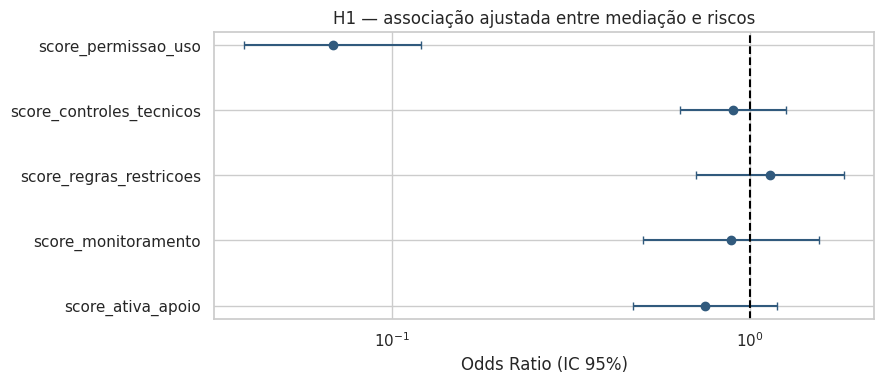

/tmp/ipykernel_36964/183099568.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plot=df.groupby(['nivel_mediacao','faixa_etaria'],observed=True).apply(


,nivel_mediacao,faixa_etaria,prevalencia_ponderada
0,Baixa,9–10,0.011767
1,Baixa,11–12,0.047548
2,Baixa,13–14,0.187329
3,Baixa,15–17,0.308991
4,Média,9–10,0.025309
5,Média,11–12,0.156501
6,Média,13–14,0.163202
7,Média,15–17,0.249310
8,Alta,9–10,0.036858
9,Alta,11–12,0.177393


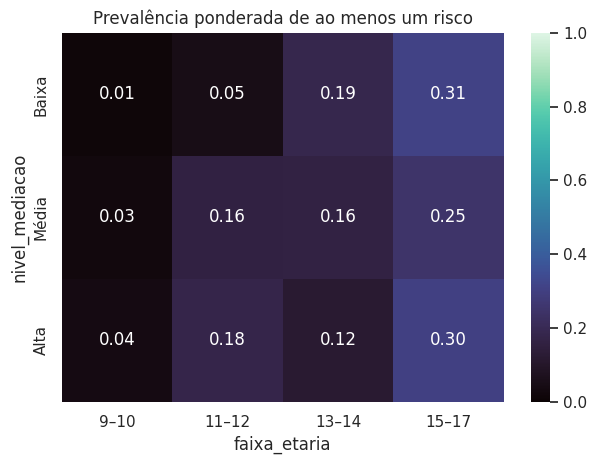

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid',context='notebook')
forest=logit_results[(logit_results.desfecho=='sofreu_algum_risco')&(logit_results.ponderado==False)&(logit_results.termo.isin(predictors))] if len(logit_results) else pd.DataFrame()
if len(forest):
    fig,ax=plt.subplots(figsize=(9,max(4,.45*len(forest))))
    y=np.arange(len(forest)); ax.errorbar(forest.OR,y,xerr=[forest.OR-forest.IC95_inf,forest.IC95_sup-forest.OR],fmt='o',capsize=3,color='#315a7d')
    ax.axvline(1,color='black',linestyle='--'); ax.set_yticks(y,forest.termo); ax.set_xscale('log'); ax.set_xlabel('Odds Ratio (IC 95%)'); ax.set_title('H1 — associação ajustada entre mediação e riscos'); plt.tight_layout(); plt.show()
else: print('Forest plot não disponível: resultado não estimável.')

plot=df.groupby(['nivel_mediacao','faixa_etaria'],observed=True).apply(
    lambda g: np.average(g.sofreu_algum_risco.dropna(),weights=g.loc[g.sofreu_algum_risco.notna(),'peso'])
    if g.sofreu_algum_risco.notna().any() else np.nan).rename('prevalencia_ponderada').reset_index()
display(plot)
if len(plot):
    sns.heatmap(plot.pivot(index='nivel_mediacao',columns='faixa_etaria',values='prevalencia_ponderada'),annot=True,fmt='.2f',vmin=0,vmax=1,cmap='mako')
    plt.title('Prevalência ponderada de ao menos um risco'); plt.tight_layout(); plt.show()


## 11. Síntese, decisão estatística e limites
A conclusão deve informar direção, tamanho de efeito, IC, p bruto e p ajustado por FDR/Bonferroni. Não rejeitar H0 não equivale a provar ausência de associação. A análise não estima mediação causal, e associações transversais podem refletir causalidade reversa: responsáveis podem intensificar monitoramento depois de um incidente.

In [55]:
def concise_verdict(table):
    if table.empty or 'p_valor_ajustado_FDR' not in table: return 'Não estimável.'
    significant=int((table.p_valor_ajustado_FDR<.05).sum())
    return f'{significant} de {len(table)} resultados com p<0,05 após FDR; consultar magnitudes e ICs.'
primary_models=logit_results[(logit_results.desfecho=='sofreu_algum_risco')&(logit_results.ponderado==False)&(logit_results.termo.isin(predictors))] if len(logit_results) else pd.DataFrame()
summary=pd.DataFrame([
 {'bloco':'H1 — modelo logístico principal','síntese':concise_verdict(primary_models)},
 {'bloco':'Associações bivariadas','síntese':concise_verdict(chi_results)},
 {'bloco':'Mediação contínua × risco','síntese':concise_verdict(spearman_results)},
 {'bloco':'Poisson robusto para contagem','síntese':concise_verdict(count_results[count_results.ponderado==False] if len(count_results) else count_results)}
])
display(summary)
print('Desenho amostral: PESO foi aplicado nas estimativas ponderadas; campos explícitos de estrato/UPA não foram encontrados. A inferência deve ser interpretada como aproximação.')
print('Mensuração: o escore primário abrange exposição sexual e incômodo associado; variáveis diretas de cyberbullying, golpes, encontros com desconhecidos ou uso excessivo não foram automaticamente identificadas no dicionário. Consulte os candidatos da Seção 6.')


,bloco,síntese
0,H1 — modelo logístico principal,"1 de 5 resultados com p<0,05 após FDR; consult..."
1,Associações bivariadas,"52 de 112 resultados com p<0,05 após FDR; cons..."
2,Mediação contínua × risco,"2 de 5 resultados com p<0,05 após FDR; consult..."
3,Poisson robusto para contagem,"2 de 6 resultados com p<0,05 após FDR; consult..."


Desenho amostral: PESO foi aplicado nas estimativas ponderadas; campos explícitos de estrato/UPA não foram encontrados. A inferência deve ser interpretada como aproximação.
Mensuração: o escore primário abrange exposição sexual e incômodo associado; variáveis diretas de cyberbullying, golpes, encontros com desconhecidos ou uso excessivo não foram automaticamente identificadas no dicionário. Consulte os candidatos da Seção 6.
